<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/Numpy/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression

- Train a linear regression using closed form solution.
  - Closed form solution is preferred as it can solve our optimization problem with calculus instead of machine learning model.
- **compare the closed form model with model trained using gradient descent algorithm**.

- **Closed form**:
  - Given inputs of D dimensions
  - $x = x_1, x_2,...,x_n, x_i 𝝐 R^{D} $
  - y tragets of dimension s
  - $y = y_1, y_2,...,y_n, y_i 𝝐 R^{S} $
  - We aim to find the function that maps our inputs to our outputs
  - A linear function with 1D is $y = mx+b$ (m is the weights in this case), however, the real world data is multi dimensional and our function can evolve to it by using vectors for our inputs and weights.
  - For a mapping of dimension $D → S$ we can think of it as finding one weight and bias vector for each dimension.
  - So we can stack our weight and bias vectors to matrices and can merg them.
  - simultaneously, we adapt our input matrix with N datapoints to match the merged dimensions of weight+bias mtrix by adding a column of '1s' at the end.
  - Now, our weights become $W = [m_1, m_2,...m_s, b]^T$, $W ϵ R^{D+1𝚇S}$
  - $X = [x_1, x_2,..,x_N,1]^T$, $X ϵ R^{N 𝚇 D +1}$
  - $Y = [y_1, y_2,...,y_N]^T$,
  - At this point, we can say that the outputs 'Y' approximates 'XW' $Y ≈ XW$
  - So, our function $f: N 𝚇 D ⇒ N 𝚇 S$
  - Since we want to find the neares approximation to Y, we can tr to find the minimum of the difference between 'Y' and 'XW'. $W = min(XW-Y)$
  - we can use derivatives for this. we can derivate wrt weights and equate to 0, The equation becomes:
  - $W^* = (X^TX)^{-1}X^TY = 0$ and solve for **'W'**
  - W* denotes the optimal weights


In [2]:
from sklearn.datasets import make_moons
import numpy as np
import matplotlib.pyplot as plt

In [3]:
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

print(X.shape)
print(y.shape)

(1000, 2)
(1000,)


In [4]:
X_train = X[:700, :]
y_train = y[:700]
X_test = X[700:,:]
y_test = y[700:]

Text(0, 0.5, 'X1')

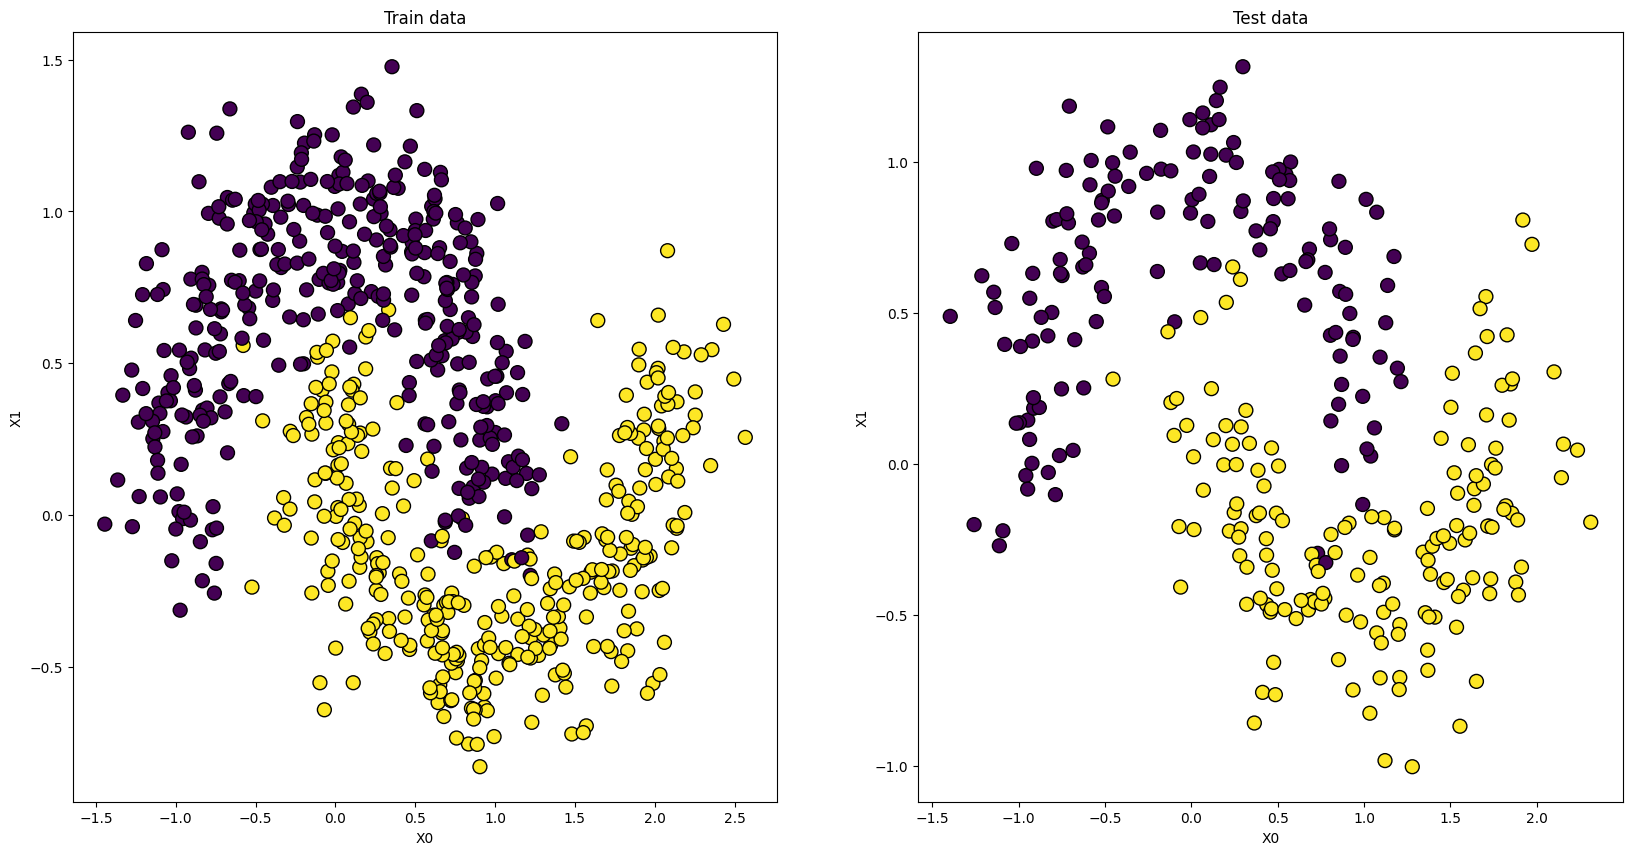

In [5]:
fig = plt.figure(figsize = (20, 10))
plt.subplot(121)
plt.scatter(X_train[:, 0], X_train[:, 1], marker='o', c=y_train.ravel(), s=100, edgecolor='k')
plt.title("Train data")
plt.xlabel("X0")
plt.ylabel("X1")
plt.subplot(122)
plt.scatter(X_test[:, 0], X_test[:, 1], marker='o', c=y_test.ravel(), s=100, edgecolor='k')
plt.title("Test data")
plt.xlabel("X0")
plt.ylabel("X1")

In [6]:
X_train_bias = np.column_stack((X_train, np.ones(len(X_train))))
X_test_bias = np.column_stack((X_test, np.ones(len(X_test))))

- we will now create a function to predict output once we calculated the weights matrix

In [7]:
def predict_output(X, weights):
  prod = np.matmul(X,weights)
  result = (prod >0.5).astype(int)
  return result

In [8]:
weights_mat = np.matmul(np.linalg.inv(np.matmul(X_train_bias.T, X_train_bias)), np.matmul(X_train_bias.T, y_train))
print("The weights matrix is: ", weights_mat)


The weights matrix is:  [ 0.17278314 -0.57484867  0.55936036]


In [9]:
#predict the test data
y_test_hat = predict_output(X_test_bias, weights_mat)
acc = float((y_test_hat == y_test).sum())/float(len(y_test))
print('The accuracy of the linear model in closed form is: ', acc)

The accuracy of the linear model in closed form is:  0.9033333333333333


- line equation = $0 = Ax+By+C$
- $y = mx+C$
- but we have thresholded at 0.5
- therefore: $0.5 = W_0x+ W_1y + W_2$
_ and $y = - \frac{W_0x + W_2 - 0.5}{W_1}$

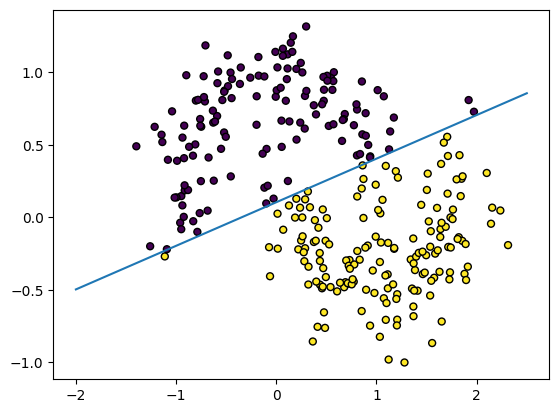

In [10]:
x_values = np.linspace(-2, 2.5, 300)
y_values = -((weights_mat[0])*x_values + weights_mat[2] - 0.5)/weights_mat[1]
plt.plot(x_values, y_values)
plt.scatter(X_test[:, 0], X_test[:, 1], marker='o', c=y_test_hat.ravel(), s=25, edgecolor='k')

## Training with gradient descent

- The loss function MSE for linear regression is a **convex function**. So using gradient descent gaurantee that the function reaches global minimum.
- The loss function is : $MSE(Θ) = \frac{1}{m} ∑_{i =1}^{m} \|Θ^T x_i - y_i \|^2 $

- Then the gradient of this function wrt to Θ can be calculated with: $ Δ_Θ MSE(Θ) = \frac{2}{m} X^T(XΘ - Y) $

- Once these losses are calculated then the Θ can be upated iteratively every step using: $ Θ^{(next step)} = Θ - ηΔ_ΘMSE(Θ) $

In [11]:
def compute_grad_loss(X,y, theta):

  h = np.matmul(X, theta)
  loss = np.mean((h - y)**2)

  grad_vec = np.matmul(X.T, (h-y))/y.shape[0]
  return loss, grad_vec

In [18]:
# Initilize the parameters
theta = np.random.randn(X_test_bias.shape[1],1)
print('theta shape:', theta.shape)
learning_rate = 0.5
n_epochs = 50

# Ensure targets are column vectors to match theta's shape
y_train_col = y_train[:, np.newaxis]
y_test_col = y_test[:, np.newaxis]

#track the loss and accuracy
loss = []
acc = []

#start the training loop
for curr_epoch in range(n_epochs):
  y_test_hat = predict_output(X_test_bias, theta)

  # calculate accuracy
  temp_acc = float((y_test_hat == y_test_col).sum()) / float(len(y_test_col))
  acc.append(temp_acc)

  # calculate the loss and gradient vectors using the column vector version of targets
  t_loss, grad_vec = compute_grad_loss(X_train_bias, y_train_col, theta)
  loss.append(t_loss)

  # update theta
  theta -= learning_rate*grad_vec

print("-"*50)
print(f'The accuracy of the model is: {acc[-1]*100}%')
print(f'Final theta values are:\n{theta}')

theta shape: (3, 1)
--------------------------------------------------
The accuracy of the model is: 90.33333333333333%
Final theta values are:
[[ 0.17688007]
 [-0.56354443]
 [ 0.55316007]]


Text(0.5, 1.0, 'accuracy of the model per epoch')

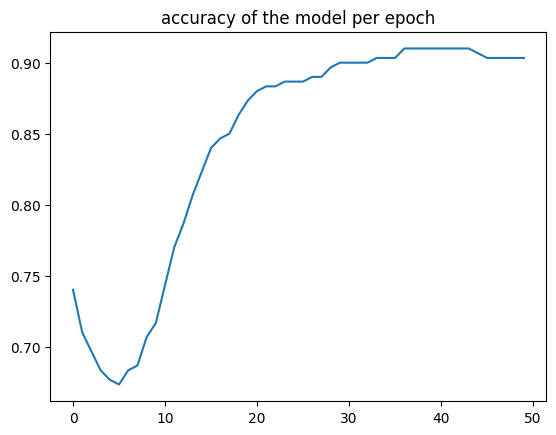

In [19]:
plt.plot(acc)
plt.title("accuracy of the model per epoch")

Summary:
- From the comparision, we can see that the Gradient descent achieved the same accuracy score as the closed form solution which is 90.333%